In [5]:
import torch
import torch.optim as opt
import numpy as np
import matplotlib.pyplot as plt

In [7]:
loss_function = lambda xy: torch.sin(xy[0]) * torch.cos(xy[1])

In [9]:
dir(torch.optim)[:16]

['ASGD',
 'Adadelta',
 'Adafactor',
 'Adagrad',
 'Adam',
 'AdamW',
 'Adamax',
 'LBFGS',
 'Muon',
 'NAdam',
 'Optimizer',
 'RAdam',
 'RMSprop',
 'Rprop',
 'SGD',
 'SparseAdam']

In [11]:
initial_position = (10.0, 10.0)
epochs = 1000
lr = 1e-1

In [13]:
def get_history_by_optimizer(optimizer_current, **kwargs):
  history = []

  xy = torch.tensor(initial_position, requires_grad=True)
  optimizer = optimizer_current([xy], **kwargs)

  for epoch in range(epochs):
    history += [xy.detach().clone().numpy()]

    optimizer.zero_grad()  
    loss = loss_function(xy) 
    loss.backward()
    optimizer.step()

  return np.array(history)

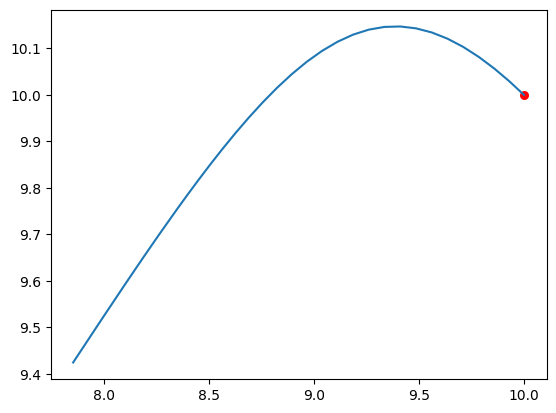

In [15]:
plt.scatter(initial_position[0], initial_position[1], c='red', s=30)
res = get_history_by_optimizer(opt.SGD, lr=lr)
plt.plot(res[:, 0], res[:, 1])
plt.show()

In [26]:
exclude = ['Optimizer', 'Muon', 'SparseAdam'] 
optimizers = {oprimizer: getattr(opt, oprimizer) for oprimizer in dir(opt)[:16] if oprimizer not in exclude}
print(optimizers)

{'ASGD': <class 'torch.optim.asgd.ASGD'>, 'Adadelta': <class 'torch.optim.adadelta.Adadelta'>, 'Adafactor': <class 'torch.optim.Adafactor'>, 'Adagrad': <class 'torch.optim.adagrad.Adagrad'>, 'Adam': <class 'torch.optim.adam.Adam'>, 'AdamW': <class 'torch.optim.adamw.AdamW'>, 'Adamax': <class 'torch.optim.adamax.Adamax'>, 'LBFGS': <class 'torch.optim.lbfgs.LBFGS'>, 'NAdam': <class 'torch.optim.nadam.NAdam'>, 'RAdam': <class 'torch.optim.radam.RAdam'>, 'RMSprop': <class 'torch.optim.rmsprop.RMSprop'>, 'Rprop': <class 'torch.optim.rprop.Rprop'>, 'SGD': <class 'torch.optim.sgd.SGD'>}


In [27]:
def plot_optimizer(name: str, history: list) -> None:
    plt.title(name)
    plt.scatter(initial_position[0], initial_position[1], c='red', s=30)
    plt.plot(history[:, 0], history[:, 1])
    plt.show()

ASGD


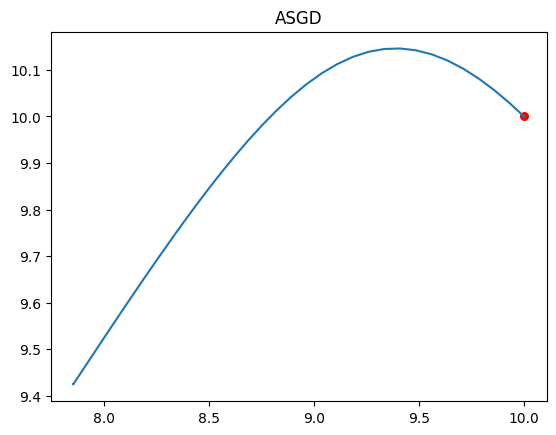

Adadelta


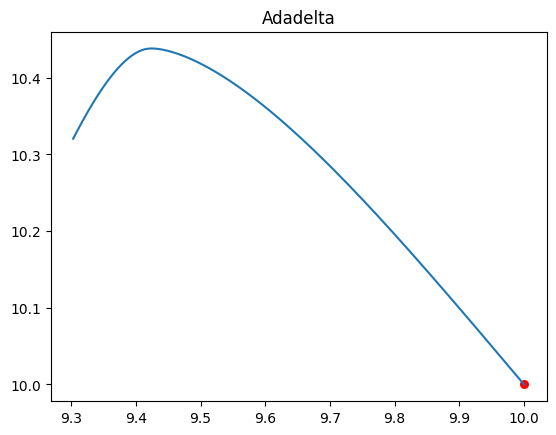

Adafactor


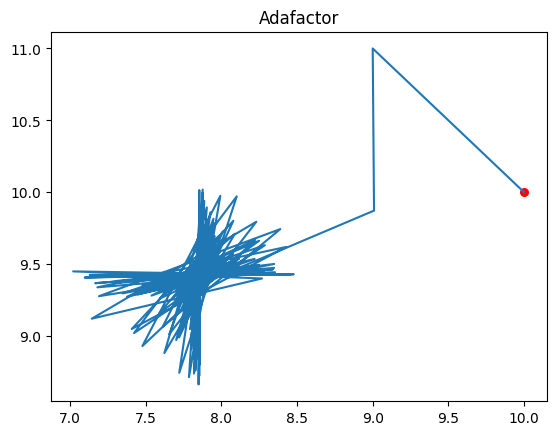

Adagrad


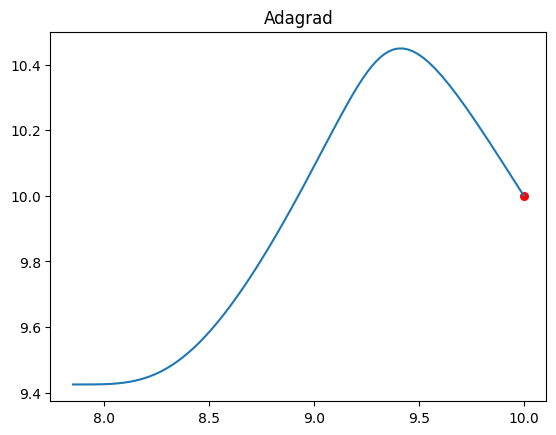

Adam


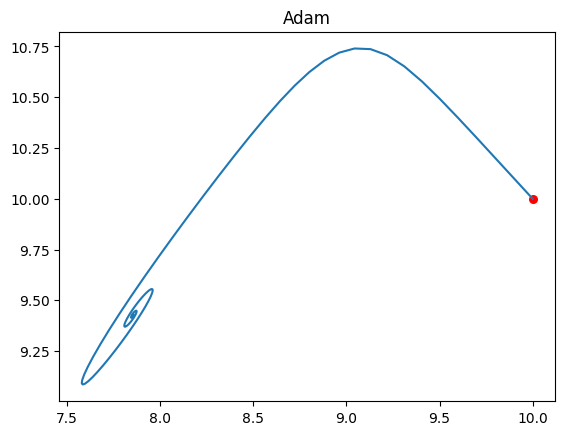

AdamW


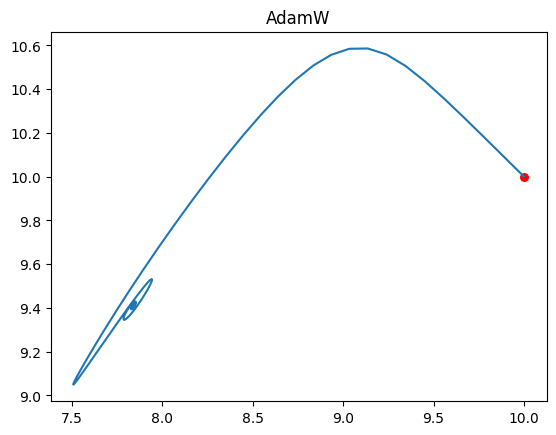

Adamax


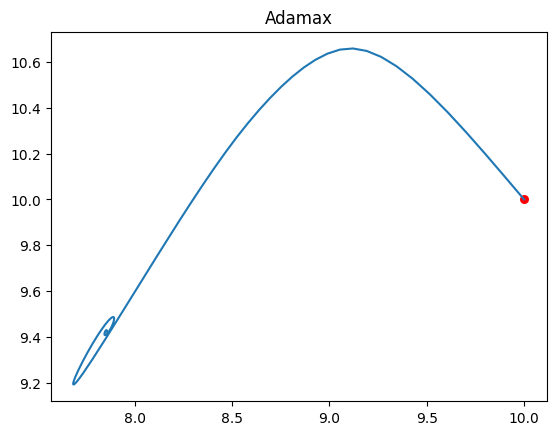

LBFGS
NAdam


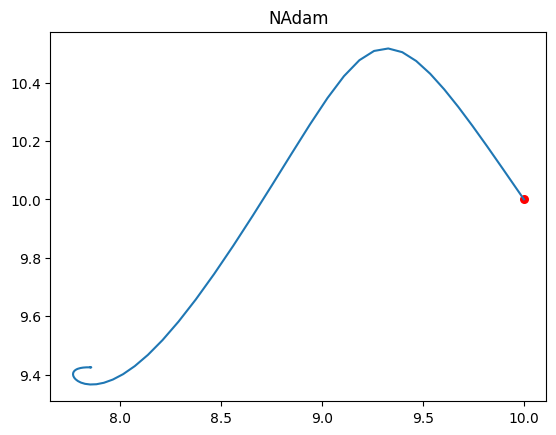

RAdam


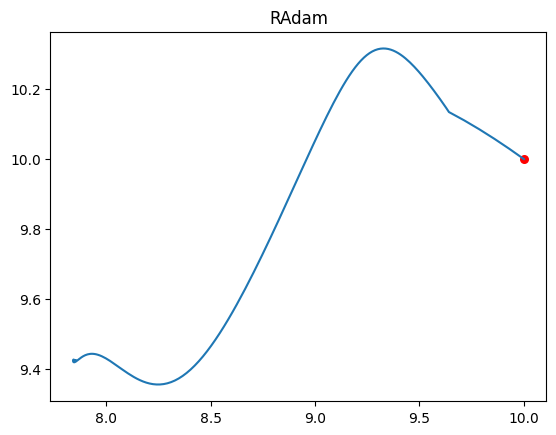

RMSprop


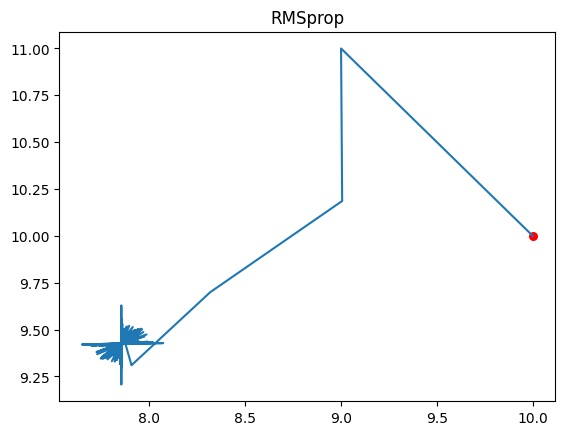

Rprop


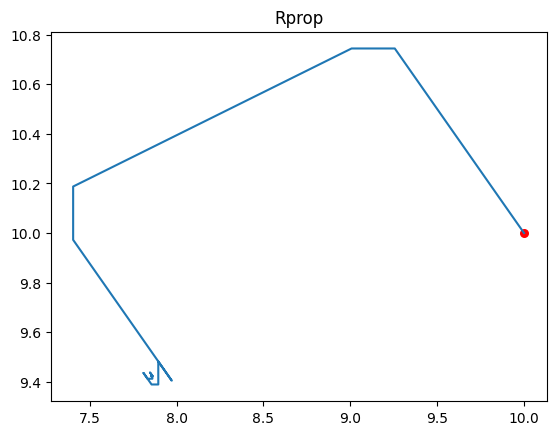

SGD


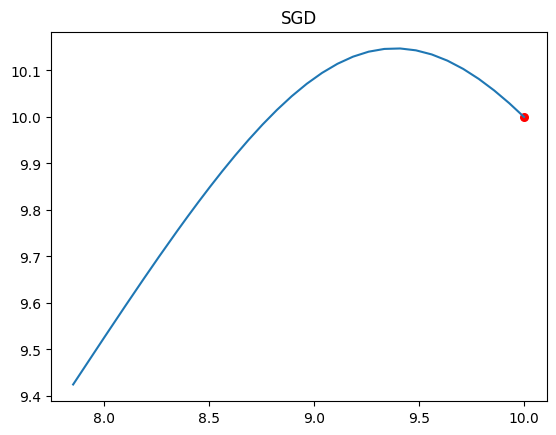

In [30]:
for name, oprimizer in optimizers.items():
    print(name)
    try:
        history = get_history_by_optimizer(oprimizer, lr=lr)
        plot_optimizer(name, history)
    except:
        pass